<a href="https://colab.research.google.com/github/Ekasjot/Exam-Score-Prediction/blob/main/Untitled11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [47]:
xdf = pd.read_csv("Exam_Score_Prediction.csv")

In [48]:
df.head()

,age,gender,course,study_hours,class_attendance,internet_access,sleep_hours,sleep_quality,study_method,facility_rating,exam_difficulty,exam_score
0,17,1,6,2.78,92.9,1,7.4,2,0,1,1,58.9
1,23,2,5,3.37,64.8,1,4.6,0,3,2,2,54.8
2,22,1,1,7.88,76.8,1,8.5,2,0,0,2,90.3
3,20,2,6,0.67,48.4,1,5.8,0,3,1,2,29.7
4,20,0,6,0.89,71.6,1,9.8,2,0,1,2,43.7


In [49]:
df.isnull().sum()

,0
age,0
gender,0
course,0
study_hours,0
class_attendance,0
internet_access,0
sleep_hours,0
sleep_quality,0
study_method,0
facility_rating,0


In [50]:
df.duplicated().sum()

np.int64(0)

In [51]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age               20000 non-null  int64  
 1   gender            20000 non-null  int64  
 2   course            20000 non-null  int64  
 3   study_hours       20000 non-null  float64
 4   class_attendance  20000 non-null  float64
 5   internet_access   20000 non-null  int64  
 6   sleep_hours       20000 non-null  float64
 7   sleep_quality     20000 non-null  int64  
 8   study_method      20000 non-null  int64  
 9   facility_rating   20000 non-null  int64  
 10  exam_difficulty   20000 non-null  int64  
 11  exam_score        20000 non-null  float64
dtypes: float64(4), int64(8)
memory usage: 1.8 MB


### 1. Drop `student_id` and Display Statistical Summary

In [52]:
# Drop the student_id column from df
if 'student_id' in df.columns:
    df = df.drop(columns=['student_id'])

# Display statistical description
display(df.describe())

,age,gender,course,study_hours,class_attendance,internet_access,sleep_hours,sleep_quality,study_method,facility_rating,exam_difficulty,exam_score
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.00000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,20.473300,1.007350,2.998600,4.007604,70.017365,0.849400,7.00856,0.999650,2.011650,1.007900,1.186850,62.513225
std,2.284458,0.815616,1.999599,2.308313,17.282262,0.357667,1.73209,0.817975,1.422152,0.817356,0.875257,18.908491
min,17.000000,0.000000,0.000000,0.080000,40.600000,0.000000,4.10000,0.000000,0.000000,0.000000,0.000000,19.599000
25%,18.000000,0.000000,1.000000,2.000000,55.100000,1.000000,5.50000,0.000000,1.000000,0.000000,0.000000,48.800000
50%,20.000000,1.000000,3.000000,4.040000,69.900000,1.000000,7.00000,1.000000,2.000000,1.000000,1.000000,62.600000
75%,22.000000,2.000000,5.000000,6.000000,85.000000,1.000000,8.50000,2.000000,3.000000,2.000000,2.000000,76.300000
max,24.000000,2.000000,6.000000,7.910000,99.400000,1.000000,9.90000,2.000000,4.000000,2.000000,2.000000,100.000000


### 2. Distribution of the Target Variable (`exam_score`)

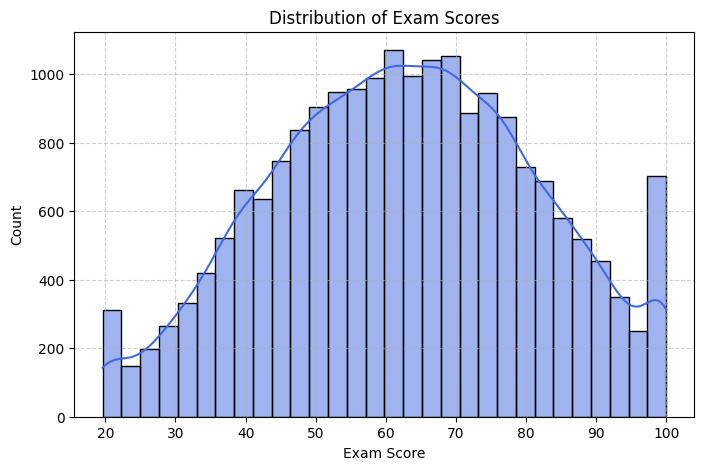

In [53]:
plt.figure(figsize=(8, 5))
sns.histplot(df['exam_score'], kde=True, bins=30, color='royalblue')
plt.title('Distribution of Exam Scores')
plt.xlabel('Exam Score')
plt.ylabel('Count')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### 3. Correlation Matrix (Numerical Features vs Exam Score)

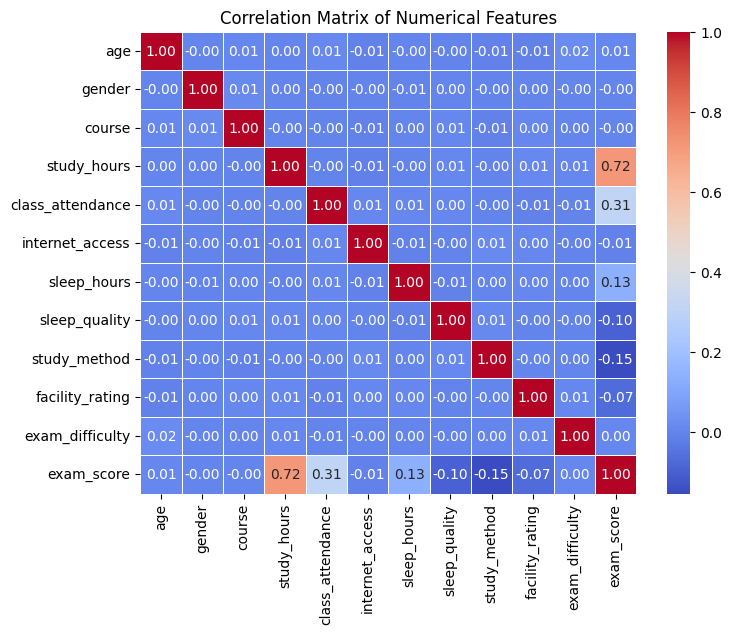

In [54]:
numerical_cols = df.select_dtypes(include=[np.number]).columns
plt.figure(figsize=(8, 6))
sns.heatmap(df[numerical_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Numerical Features')
plt.show()

### 4. Relationship of Key Features with `exam_score`

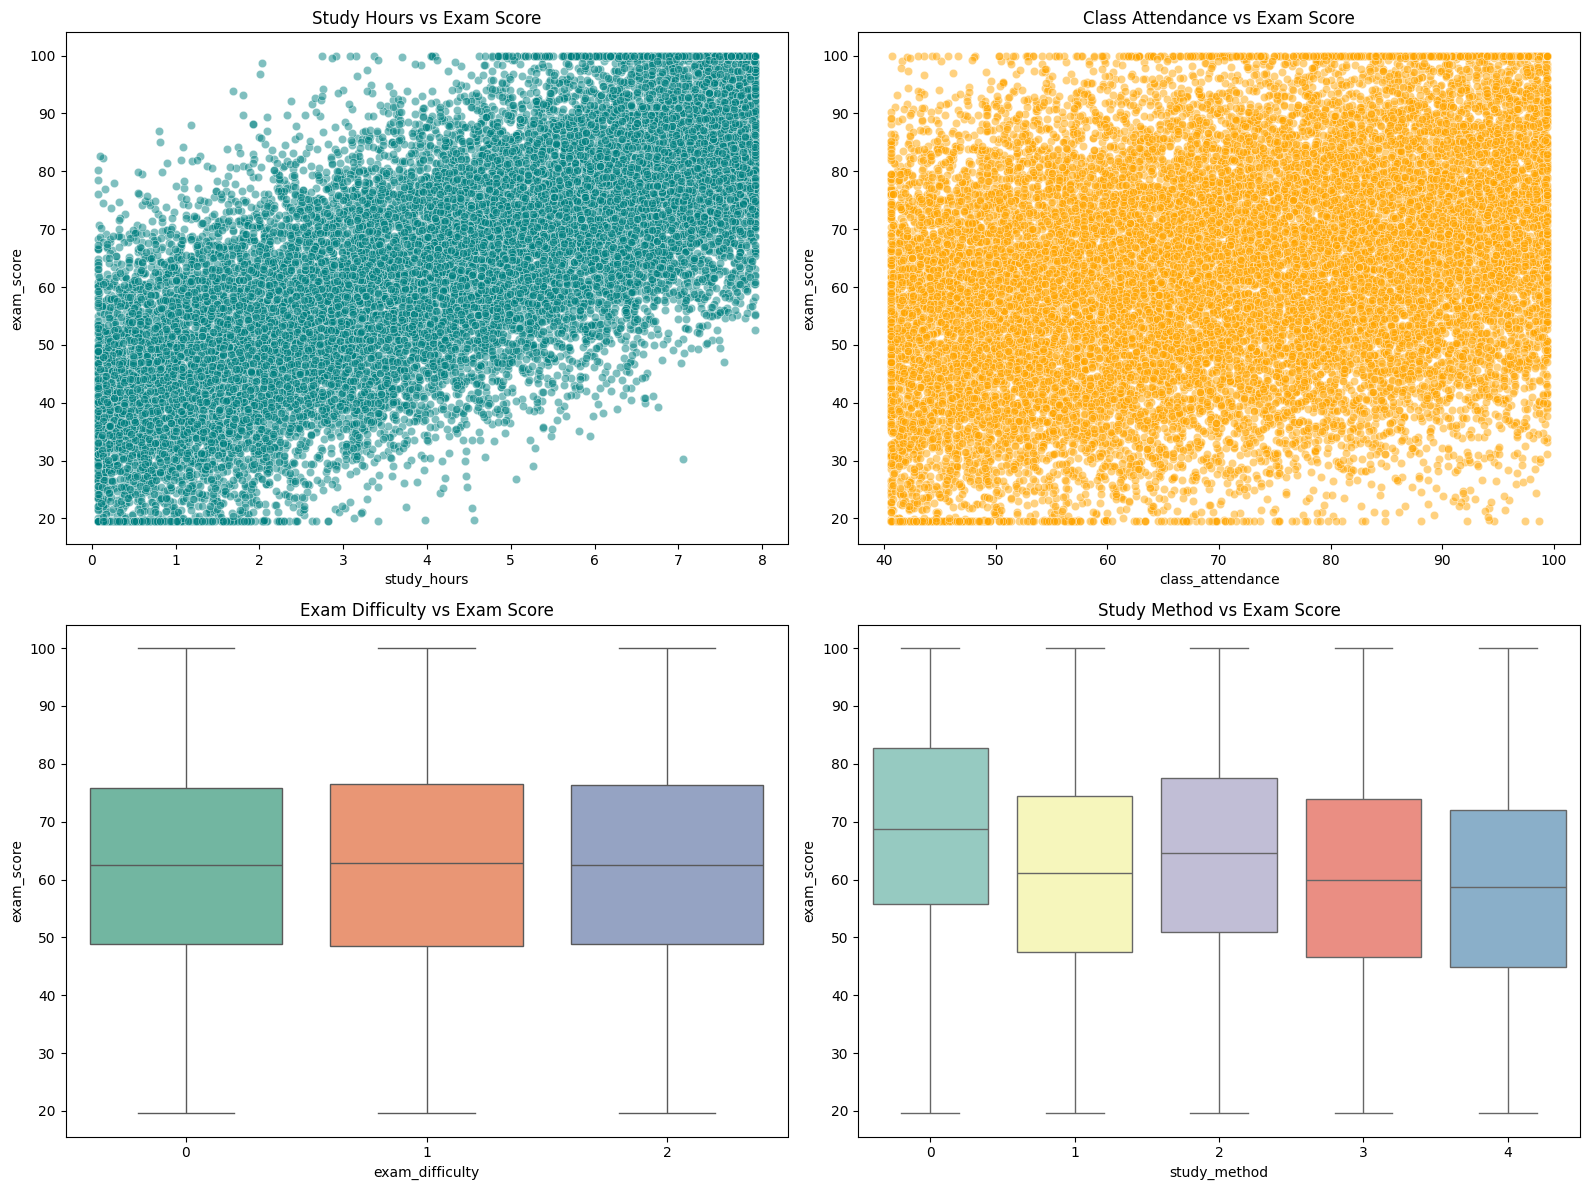

In [55]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Study Hours vs Exam Score
sns.scatterplot(ax=axes[0, 0], data=df, x='study_hours', y='exam_score', alpha=0.5, color='teal')
axes[0, 0].set_title('Study Hours vs Exam Score')

# Class Attendance vs Exam Score
sns.scatterplot(ax=axes[0, 1], data=df, x='class_attendance', y='exam_score', alpha=0.5, color='orange')
axes[0, 1].set_title('Class Attendance vs Exam Score')

# Exam Difficulty vs Exam Score
sns.boxplot(ax=axes[1, 0], data=df, x='exam_difficulty', y='exam_score', palette='Set2')
axes[1, 0].set_title('Exam Difficulty vs Exam Score')

# Study Method vs Exam Score
sns.boxplot(ax=axes[1, 1], data=df, x='study_method', y='exam_score', palette='Set3')
axes[1, 1].set_title('Study Method vs Exam Score')

plt.tight_layout()
plt.show()

### 5. Statistical Significance Testing on Categorical Features (and Age)
We will use standard statistical tests to verify if the variations in `exam_score` across categories are statistically significant:
* **One-Way ANOVA** for features with 3 or more categories (including `age`).
* **Two-Sample T-Test** for binary features (`internet_access`).

In [56]:
import scipy.stats as stats

# List of categorical columns to test
categorical_cols = ['gender', 'course', 'sleep_quality', 'study_method', 'facility_rating', 'exam_difficulty', 'age']
binary_cols = ['internet_access']

print("=== ONE-WAY ANOVA TESTS (Target: exam_score) ===\n")
for col in categorical_cols:
    # Group exam scores by category
    categories = df[col].unique()
    groups = [df[df[col] == cat]['exam_score'] for cat in categories]

    # Run ANOVA
    f_stat, p_val = stats.f_oneway(*groups)
    print(f"{col.upper():<16}: F-Statistic = {f_stat:.4f}, p-value = {p_val:.4e}")
    if p_val < 0.05:
        print(f"  -> Statistically Significant: Yes (different categories have significantly different mean exam scores)\n")
    else:
        print(f"  -> Statistically Significant: No (no significant difference between category means)\n")

print("=== TWO-SAMPLE T-TESTS (Target: exam_score) ===\n")
for col in binary_cols:
    categories = df[col].unique()
    if len(categories) == 2:
        group1 = df[df[col] == categories[0]]['exam_score']
        group2 = df[df[col] == categories[1]]['exam_score']

        t_stat, p_val = stats.ttest_ind(group1, group2, equal_var=False)
        print(f"{col.upper():<16}: T-Statistic = {t_stat:.4f}, p-value = {p_val:.4e}")
        if p_val < 0.05:
            print(f"  -> Statistically Significant: Yes\n")
        else:
            print(f"  -> Statistically Significant: No\n")

=== ONE-WAY ANOVA TESTS (Target: exam_score) ===

GENDER          : F-Statistic = 0.1906, p-value = 8.2646e-01
  -> Statistically Significant: No (no significant difference between category means)

COURSE          : F-Statistic = 0.6144, p-value = 7.1900e-01
  -> Statistically Significant: No (no significant difference between category means)

SLEEP_QUALITY   : F-Statistic = 411.7933, p-value = 5.5607e-176
  -> Statistically Significant: Yes (different categories have significantly different mean exam scores)

STUDY_METHOD    : F-Statistic = 180.5267, p-value = 3.1987e-152
  -> Statistically Significant: Yes (different categories have significantly different mean exam scores)

FACILITY_RATING : F-Statistic = 273.7664, p-value = 5.0507e-118
  -> Statistically Significant: Yes (different categories have significantly different mean exam scores)

EXAM_DIFFICULTY : F-Statistic = 0.2370, p-value = 7.8902e-01
  -> Statistically Significant: No (no significant difference between category mean

### 6. Label Encoding of Categorical Variables
We will encode all categorical columns (features with `object` data type) to prepare them for machine learning models.

In [57]:
from sklearn.preprocessing import LabelEncoder

# Identify categorical columns (excluding the target 'exam_score')
categorical_features = df.select_dtypes(include=['object']).columns.tolist()

# Initialize a dictionary to store encoders for future inverse transforming if needed
label_encoders = {}

# Apply LabelEncoder to each categorical column
for col in categorical_features:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].astype(str))
    label_encoders[col] = le
    print(f"Encoded column '{col}' successfully.")

# Display the encoded dataframe's first few rows
display(df.head())

,age,gender,course,study_hours,class_attendance,internet_access,sleep_hours,sleep_quality,study_method,facility_rating,exam_difficulty,exam_score
0,17,1,6,2.78,92.9,1,7.4,2,0,1,1,58.9
1,23,2,5,3.37,64.8,1,4.6,0,3,2,2,54.8
2,22,1,1,7.88,76.8,1,8.5,2,0,0,2,90.3
3,20,2,6,0.67,48.4,1,5.8,0,3,1,2,29.7
4,20,0,6,0.89,71.6,1,9.8,2,0,1,2,43.7


In [58]:
X = df.drop(['exam_score','age','gender','internet_access','exam_difficulty','course'], axis=1)
y = df['exam_score']

In [59]:
from sklearn.model_selection import train_test_split
_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33,random_state=42)


In [60]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error,r2_score

### 7. Decision Tree Regressor Model Training & Performance Evaluation

In [61]:
# Initialize Decision Tree Regressor
dt_regressor = DecisionTreeRegressor(random_state=42)

# Train the model
dt_regressor.fit(_train, y_train)

# Make predictions on the test set
y_pred = dt_regressor.predict(X_test)

# Calculate metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Display the metrics
print("=== DECISION TREE REGRESSOR PERFORMANCE ===\n")
print(f"Mean Squared Error (MSE)      : {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE)     : {mae:.4f}")
print(f"R-squared (R2) Score          : {r2}")

=== DECISION TREE REGRESSOR PERFORMANCE ===

Mean Squared Error (MSE)      : 216.8873
Root Mean Squared Error (RMSE): 14.7271
Mean Absolute Error (MAE)     : 11.7025
R-squared (R2) Score          : 0.3985925819540924


In [62]:
from sklearn.ensemble import AdaBoostRegressor

In [66]:
adaboost_regressor = AdaBoostRegressor(random_state=42)
adaboost_regressor.fit(_train, y_train)

y_pred = adaboost_regressor.predict(X_test)

mse_ada = mean_squared_error(y_test, y_pred)
rmse_ada = np.sqrt(mse_ada)
mae_ada = mean_absolute_error(y_test, y_pred)
r2_ada = r2_score(y_test, y_pred)

print("=== ADABOOST REGRESSOR PERFORMANCE ===\n")
print(f"Mean Squared Error (MSE)      : {mse_ada:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_ada:.4f}")
print(f"Mean Absolute Error (MAE)     : {mae_ada:.4f}")
print(f"R-squeared Score: {r2_ada}")

=== ADABOOST REGRESSOR PERFORMANCE ===

Mean Squared Error (MSE)      : 117.9360
Root Mean Squared Error (RMSE): 10.8598
Mean Absolute Error (MAE)     : 8.8796
R-squeared Score: 0.6729748250102305


In [67]:
from xgboost import XGBRegressor
xgb_regressor = XGBRegressor(random_state=42)
xgb_regressor.fit(_train, y_train)

y_pred = xgb_regressor.predict(X_test)

mse_xgb = mean_squared_error(y_test, y_pred)
rmse_xgb = np.sqrt(mse_xgb)
mae_xgb = mean_absolute_error(y_test, y_pred)
r2_xgb = r2_score(y_test, y_pred)

print("=== XGBOOST REGRESSOR PERFORMANCE ===\n")
print(f"Mean Squared Error (MSE)      : {mse_xgb:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_xgb:.4f}")
print(f"Mean Absolute Error (MAE)     : {mae_xgb:.4f}")
print(f"R-Squared Score: {r2_xgb}")

=== XGBOOST REGRESSOR PERFORMANCE ===

Mean Squared Error (MSE)      : 109.0927
Root Mean Squared Error (RMSE): 10.4447
Mean Absolute Error (MAE)     : 8.3760
R-Squared Score: 0.697496526820415


### 8. Hyperparameter Tuning for XGBoost using GridSearchCV
We will define a parameter grid and search for the best configuration using 3-Fold Cross Validation.

In [68]:
from sklearn.model_selection import GridSearchCV

# Define the parameter grid
param_grid = {
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.05, 0.1],
    'n_estimators': [100, 200, 300],
    'subsample': [0.8, 1.0]
}

# Initialize the XGBRegressor base model
xgb_base = XGBRegressor(random_state=42)

# Set up GridSearchCV with 3-fold cross-validation
grid_search = GridSearchCV(
    estimator=xgb_base,
    param_grid=param_grid,
    cv=3,
    scoring='neg_mean_squared_error',
    verbose=1,
    n_jobs=-1
)

# Fit the grid search to the training data
grid_search.fit(_train, y_train)

# Get the best parameters and model
best_params = grid_search.best_params_
best_xgb = grid_search.best_estimator_

print("=== BEST PARAMETERS FOUND ===")
for param, val in best_params.items():
    print(f"{param}: {val}")

Fitting 3 folds for each of 54 candidates, totalling 162 fits
=== BEST PARAMETERS FOUND ===
learning_rate: 0.05
max_depth: 3
n_estimators: 300
subsample: 0.8


### 9. Evaluate the Tuned XGBoost Model on the Test Set

In [69]:
# Predict using the tuned model
y_pred_tuned = best_xgb.predict(X_test)

# Calculate metrics
mse_tuned = mean_squared_error(y_test, y_pred_tuned)
rmse_tuned = np.sqrt(mse_tuned)
mae_tuned = mean_absolute_error(y_test, y_pred_tuned)
r2_tuned = r2_score(y_test, y_pred_tuned)

# Display the metrics
print("=== TUNED XGBOOST REGRESSOR PERFORMANCE ===\n")
print(f"Mean Squared Error (MSE)      : {mse_tuned:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_tuned:.4f}")
print(f"Mean Absolute Error (MAE)     : {mae_tuned:.4f}")
print(f"R-Squared (R2) Score          : {r2_tuned:.4f}")

=== TUNED XGBOOST REGRESSOR PERFORMANCE ===

Mean Squared Error (MSE)      : 97.0131
Root Mean Squared Error (RMSE): 9.8495
Mean Absolute Error (MAE)     : 7.9351
R-Squared (R2) Score          : 0.7310


### 10. Save Label Encoders and Tuned Model to Pickle Files
We will use the standard `pickle` library to save the fitted encoders and the tuned XGBoost model to files so that they can be easily loaded and reused in other applications.

In [70]:
import pickle

# Save the dictionary of fitted label encoders
encoders_filename = 'label_encoders.pkl'
with open(encoders_filename, 'wb') as file:
    pickle.dump(encoders, file)
print(f"Fitted label encoders successfully saved to '{encoders_filename}'")

# Save the best hyperparameter-tuned XGBoost model
model_filename = 'xgboost_model.pkl'
with open(model_filename, 'wb') as file:
    pickle.dump(best_xgb, file)
print(f"Tuned XGBoost model successfully saved to '{model_filename}'")

Fitted label encoders successfully saved to 'label_encoders.pkl'
Tuned XGBoost model successfully saved to 'xgboost_model.pkl'


In [71]:
import pickle

# Filter the encoders dictionary to only keep the features that are actually in X
active_features = [col for col in X.columns if col in encoders]
filtered_encoders = {col: encoders[col] for col in active_features}

# Save the filtered label encoders
with open('label_encoders.pkl', 'wb') as file:
    pickle.dump(filtered_encoders, file)

print("Saved updated 'label_encoders.pkl' containing only encoders for active features:", list(filtered_encoders.keys()))

Saved updated 'label_encoders.pkl' containing only encoders for active features: ['sleep_quality', 'study_method', 'facility_rating']


In [72]:

import pickle

# Save the final tuned model
with open('xgboost_model.pkl', 'wb') as f:
    pickle.dump(best_xgb, f, protocol=pickle.HIGHEST_PROTOCOL)

# Save only the required encoders
active_features = ['sleep_quality', 'study_method', 'facility_rating']

filtered_encoders = {
    col: encoders[col] for col in active_features
}

with open('label_encoders.pkl', 'wb') as f:
    pickle.dump(filtered_encoders, f, protocol=pickle.HIGHEST_PROTOCOL)

print("Both files saved successfully!")

# Verify both files immediately
with open('xgboost_model.pkl', 'rb') as f:
    test_model = pickle.load(f)

with open('label_encoders.pkl', 'rb') as f:
    test_encoders = pickle.load(f)

print("Model verification successful:", type(test_model))
print("Encoder verification successful:", list(test_encoders.keys()))


Both files saved successfully!
Model verification successful: <class 'xgboost.sklearn.XGBRegressor'>
Encoder verification successful: ['sleep_quality', 'study_method', 'facility_rating']


In [75]:
import pickle

with open("xgboost_model.pkl", "rb") as f:
    model = pickle.load(f)

print("Model loaded successfully!")

Model loaded successfully!


In [78]:
best_xgb.save_model("xgboost_model.json")

from google.colab import files
files.download("xgboost_model.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>